# Plot color palette for dark and light mode

In [4]:

import matplotlib.pyplot as plt

PLOT_COLORS = {
    "light": [
        "#1762A0", "#A64600", "#006D69",
        "#7840A4", "#886000"
    ],
    "dark": [
        "#67B4F2", "#FFAB66", "#53D5C3",
        "#C39BF5", "#F4D45D"
    ]
}

LINESTYLES = ["-", "--", ":", "-.", (0, (8, 3))]
MARKERS = ["o", "s", "^", "D", "x"]

def setup_plot(mode="light"):
    dark = mode == "dark"
    bg = "#17191F" if dark else "#FFFFFF"
    fg = "#F0F0F0" if dark else "#202020"

    plt.rcParams.update({
        "figure.facecolor": bg,
        "axes.facecolor": bg,
        "savefig.facecolor": bg,
        "text.color": fg,
        "axes.labelcolor": fg,
        "xtick.color": fg,
        "ytick.color": fg,
        "axes.edgecolor": fg,
        "grid.alpha": 0.18,
        "axes.prop_cycle": plt.cycler(
            color=PLOT_COLORS[mode]
        )
    })

    return PLOT_COLORS[mode]

# Plot Setup
colors = setup_plot("light")

# Für mehrere Messreihen:
# ax.plot(x, y, color=colors[i],
#         linestyle=LINESTYLES[i],
#         marker=MARKERS[i])


# Task 3

Modify the 1D Ising code. Changes to be made to
| Function   | Modification | Status |
|------------|--------------|--------|
|`delta_H()` | Account for 4 nearest neighbours instead of 2 |&#x2611;|
| `metropolis_step()` | select site using two indices |&#x2611;|
| `metropolis_sweep()` | Visit every lattice site exactly once per sweep |&#x2611;|
| `magnetization()` | No change |&#x2611;|
| `run_simulation()` | Initialize $N_x\times N_y$ spin array |&#x2611;|
| `autocorrelation()` | No change |&#x2611;|

Then estimate $\langle m \rangle$ as a function of $h\in\left[ -1,1 \right]$ for fixed $J = \{0.3, J_c, 0.7\}$. Use $N_x=N_y \in [4, 20]$

Finished J=0.300, L=4, mean magnetizations:-0.972, -0.958, -0.932, -0.873, -0.731, -0.724, -0.677, -0.629, -0.579, -0.491, -0.397, -0.269, -0.141, -0.005, 0.156, 0.275, 0.388, 0.488, 0.577, 0.629, 0.682, 0.713, 0.734, 0.879, 0.928, 0.958, 0.972
Finished J=0.300, L=8, mean magnetizations:-0.972, -0.957, -0.929, -0.874, -0.730, -0.732, -0.706, -0.665, -0.607, -0.532, -0.447, -0.339, -0.185, -0.007, 0.172, 0.338, 0.443, 0.540, 0.605, 0.649, 0.698, 0.737, 0.735, 0.874, 0.928, 0.958, 0.973
Finished J=0.300, L=12, mean magnetizations:-0.972, -0.956, -0.930, -0.875, -0.740, -0.734, -0.702, -0.661, -0.606, -0.542, -0.443, -0.327, -0.181, -0.010, 0.173, 0.335, 0.448, 0.534, 0.602, 0.654, 0.703, 0.733, 0.735, 0.875, 0.929, 0.957, 0.972
Finished J=0.300, L=16, mean magnetizations:-0.973, -0.957, -0.929, -0.873, -0.733, -0.734, -0.700, -0.656, -0.604, -0.536, -0.441, -0.325, -0.171, 0.007, 0.177, 0.330, 0.449, 0.537, 0.604, 0.658, 0.698, 0.733, 0.734, 0.875, 0.929, 0.957, 0.973
Finished J=0.300, L

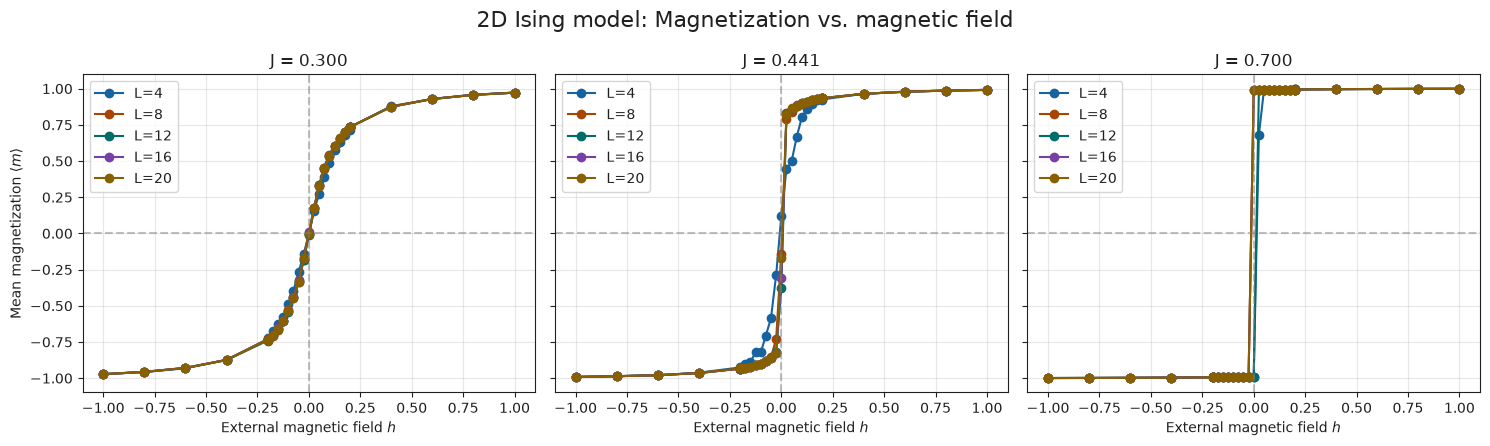

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Define some functions for the 1D Ising model 

def delta_H(spins, x, y, J=1.0, h=0.0):
    """Energy change when flipping spin (x,y)"""
    Nx, Ny = spins.shape # .shape returns a tuple of the dimensions of the array

    # Four nearest neighbours with periodic boundary conditions
    left = spins[(x - 1) % Nx, y]
    right = spins[(x + 1) % Nx, y]
    up = spins[x, (y - 1) % Ny]
    down = spins[x, (y + 1) % Ny]

    # Sum of nearest neighbours
    neighbour_sum = left+right+up+down

    # return energy difference dH
    return 2 * spins[x, y] * (J * neighbour_sum + h)

def metropolis_step(spins, x, y, T, rng, J=1.0, h=0.0): 
    """Attempt to flip spin (x,y) using Metropolis rule"""

    # Calculate local energy difference
    dH = delta_H(spins, x, y, J, h)

    # Apply Metropolis acceptance rule
    if dH <= 0 or rng.random() < np.exp(-dH / T):
        spins[x, y] *= -1

def metropolis_sweep(spins, T, rng, J=1.0, h=0.0):
    """Perform one full sweep of the 2D lattice"""
    Nx, Ny = spins.shape 

    for x in range(Nx):
        for y in range(Ny):
            metropolis_step(spins, x, y, T, rng, J, h)

def magnetization(spins):
    """Calculate the magnetization per spin m = sum(spins) / (Nx * Ny)"""
    return np.mean(spins)

def run_simulation(Nx, Ny, T, n_therm, n_meas, rng, J=1.0, h=0.0):
    """Run Metropolis sim for 2D Ising model"""

    # init all spins to +1
    # spins = np.ones((Nx, Ny), dtype=int) ## doesnt work: traps in metastable state for h<0 and strong J with positive magnetization

    # Initialize according to external field h
    # explanation see PDF
    if h > 0:
        spins = np.ones((Nx, Ny), dtype=int) # All spins up
    elif h < 0:
        spins = -np.ones((Nx, Ny), dtype=int) # All spins down
    else:
        spins = rng.choice([-1, 1], size=(Nx, Ny)) # Random initial configuration for h=0

    # Thermalization
    thermal_history = np.empty(n_therm)

    for k in range(n_therm):
        metropolis_sweep(spins, T, rng, J, h)
        thermal_history[k] = magnetization(spins)

    # Measurement 
    measurements = np.empty(n_meas)

    for k in range(n_meas):
        metropolis_sweep(spins, T, rng, J, h)
        measurements[k] = magnetization(spins)

    meas_mean = np.mean(measurements)

    return meas_mean, measurements, thermal_history

# ============================================================
# Task 3: Megnetization <m> as function of magnetic field h

J_c = 0.5 * np.log(1 + np.sqrt(2))  # critical coupling value

J_vals = [0.3, J_c, 0.7] # different coupling values
L_vals = [4, 8, 12, 16, 20] # different lattice sizes
h_vals = np.unique(np.concatenate([
    np.linspace(-1, 1, 11), # magnetic field values
    np.linspace(-0.2, 0.2, 17) # more values around h=0
]))

T = 1.0
n_therm = 2000
n_meas = 5000

rng = np.random.default_rng(seed=42)

# Store results in a dict
results = {}

for J in J_vals:
    results[J] = {}

    for L in L_vals:
        mean_values = []

        for h in h_vals:
            mean_m, measurements, _thermal_history = run_simulation(
                Nx = L,
                Ny = L,
                T = T,
                n_therm = n_therm,
                n_meas = n_meas,
                rng = rng,
                J = J,
                h = h
            )
            mean_values.append(float(mean_m))

        results[J][L] = mean_values
        print(f"Finished J={J:.3f}, L={L}, mean magnetizations:" 
              + ", ".join(f"{m:.3f}" for m in mean_values))

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)

for ax, J in zip(axes, J_vals):
    for L in L_vals:
        ax.plot(h_vals, results[J][L], label=f"L={L}", marker="o", color=colors[L_vals.index(L)])
    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.5)
    
    ax.set_title(f"J = {J:.3f}")
    ax.set_xlabel("External magnetic field $h$")
    ax.grid(alpha=0.3)
    ax.legend()


axes[0].set_ylabel(r"Mean magnetization $\langle m\rangle$")

fig.suptitle("2D Ising model: Magnetization vs. magnetic field", fontsize=16)
plt.tight_layout()
plt.show()



# # ============================================================
# # Statistical uncertainty and autocorrelation

# def autocorrelation(measurements, lag):
#     """Estimate the normalized autocorrelation at a given lag."""
#     m = np.asarray(measurements)
    
#     if lag == 0:
#         return 1.0
    
#     return np.corrcoef(m[:-lag], m[lag:])[0, 1]


# # Sample statistics
# M = len(measurements)
# sample_std = np.std(measurements, ddof=1)
# sem_naive = sample_std / np.sqrt(M)

# # Autocorrelation analysis
# max_lag = 100
# lags = np.arange(max_lag + 1)

# ac_values = np.array([
#     autocorrelation(measurements, lag) for lag in lags
#     ])

# # Integrated autocorrelation time
# cutoff = 75
# tau_int = 0.5 + np.sum(ac_values[1:cutoff + 1])

# # Effective sample size and corrected uncertainty
# M_eff = M / (2 * tau_int)
# sem_corrected = sample_std / np.sqrt(M_eff)

# # Results
# print(f"Mean magnetization:       {mean_m:.6f}")
# print(f"Sample standard deviation: {sample_std:.6f}")
# print(f"Naive SEM:                {sem_naive:.6f}")
# print(f"Autocorrelation time:     {tau_int:.4f} sweeps")
# print(f"Effective sample size:   {M_eff:.2f}")
# print(f"Corrected SEM:            {sem_corrected:.6f}")

# print(f"\nFinal estimate: <m> = {mean_m:.4f} ± {sem_corrected:.4f}")

# # Check sensitivity to the autocorrelation cutoff
# for c in [50, 75, 100]:
#     tau = 0.5 + np.sum(ac_values[1:c + 1])
#     print(f"Cutoff {c:3d}: tau_int = {tau:.3f}")

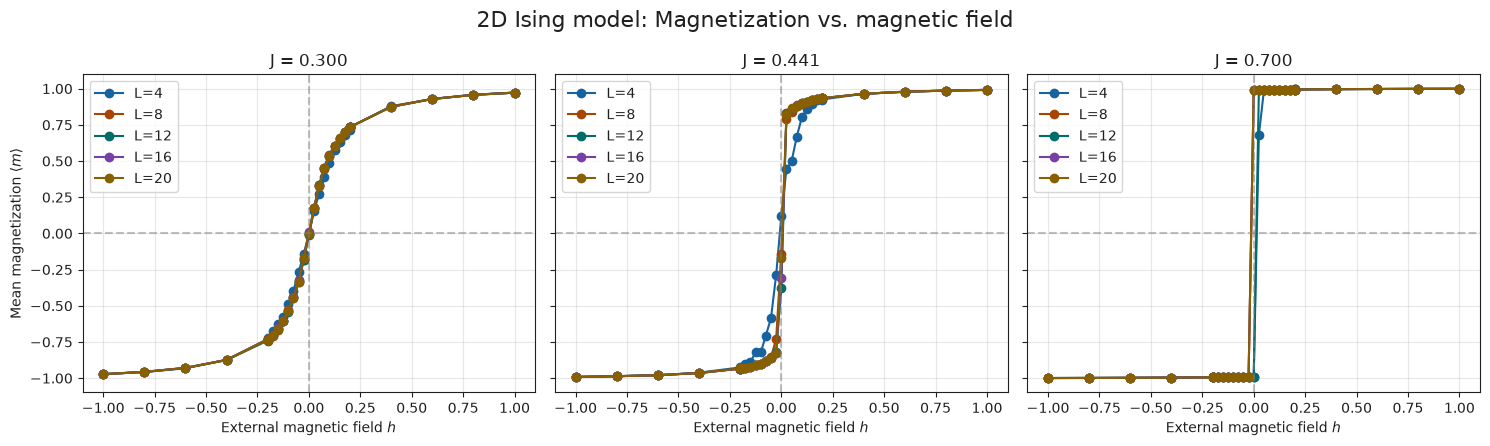

In [16]:
# Plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)

for ax, J in zip(axes, J_vals):
    for L in L_vals:
        ax.plot(h_vals, results[J][L], label=f"L={L}", marker="o", color=colors[L_vals.index(L)])
    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.5)
    
    ax.set_title(f"J = {J:.3f}")
    ax.set_xlabel("External magnetic field $h$")
    ax.grid(alpha=0.3)
    ax.legend()


axes[0].set_ylabel(r"Mean magnetization $\langle m\rangle$")

fig.suptitle("2D Ising model: Magnetization vs. magnetic field", fontsize=16)
plt.tight_layout()
plt.savefig("magnetization_vs_field_detailed.pdf", dpi=300)
plt.show()

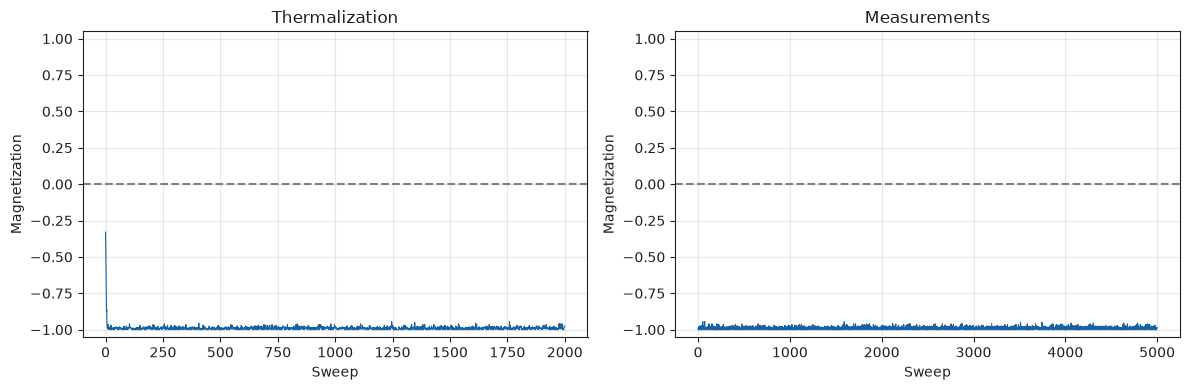

Mean magnetization: -0.9904


In [13]:
# Diagnostic: magnetization history at h = 0

rng_test = np.random.default_rng(seed=123)

mean_m, measurements, thermal_history = run_simulation(
    Nx=20,
    Ny=20,
    T=1.0,
    n_therm=2000,
    n_meas=5000,
    rng=rng_test,
    J=0.7,
    h=0.0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(thermal_history, linewidth=0.8)
axes[0].set_title("Thermalization")
axes[0].set_xlabel("Sweep")
axes[0].set_ylabel("Magnetization")

axes[1].plot(measurements, linewidth=0.8)
axes[1].set_title("Measurements")
axes[1].set_xlabel("Sweep")
axes[1].set_ylabel("Magnetization")

for ax in axes:
    ax.set_ylim(-1.05, 1.05)
    ax.axhline(0, color="gray", linestyle="--")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean magnetization: {mean_m:.4f}")